# 循环神经网络
到目前为止，我们接触过的卷积神经网络架构适合处理图像数据。

但是，我们默认数据来自于某分布并且所有样本都是**独立同分布**的，然而大多数的数据并非如此。文本中的单词是按顺序写的，假如随机打乱，很难理解文章的原意。再比如说视频中的图像帧，对话中的音频信号，网站上的浏览行为都是有顺序的。因此针对这种数据设计模型，可能效果更好。

而且，我们不仅仅可以接受一个序列作为输入，而且还可能期望继续猜测这个序列的后续

## 序列模型
回归模型：输入数据的数量会随着遇到的数据量的增加而增加，需要解决如何有效估计$P(x_t \mid x_{t-1}, \ldots, x_1)$

自回归模型：假设在现实情况下相当长的序列
$x_{t-1}, \ldots, x_1$可能是不必要的，
因此我们只需要满足某个长度为$\tau$的时间跨度，
即使用观测序列$x_{t-1}, \ldots, x_{t-\tau}$。
当下获得的最直接的好处就是参数的数量总是不变的，
至少在$t > \tau$时如此.这种模型是**用这个序列自身过去的值，预测它接下来的值**
隐变量自回归模型，如 :numref:`fig_sequence-model`所示，
是保留一些对过去观测的总结$h_t$，
并且同时更新预测$\hat{x}_t$和总结$h_t$。
这就产生了基于$\hat{x}_t = P(x_t \mid h_{t})$估计$x_t$，
以及公式$h_t = g(h_{t-1}, x_{t-1})$更新的模型。
由于$h_t$从未被观测到，这类模型也被称为
*隐变量自回归模型*（latent autoregressive models）。这种模型是**根据已经形成的理解，加上刚读到的字，更新理解，再猜接下来可能出现什么**

![隐变量自回归模型](../李沐《动手学深度学习》\d2l-zh\pytorch\img\sequence-model.svg)

## 马尔可夫模型

推导过程如下

$$
\begin{aligned}
  P(x_{t+1}\mid x_{t-1})
  &=\frac{\sum_{x_t}P(x_{t+1}\mid x_t,x_{t-1})P(x_t,x_{t-1})}
  {P(x_{t-1})}\\
  &=\frac{\sum_{x_t}P(x_{t+1}\mid x_t)
  P(x_t\mid x_{t-1})P(x_{t-1})}
  {P(x_{t-1})}\\
  &=\sum_{x_t}P(x_{t+1}\mid x_t)P(x_t\mid x_{t-1}).
  \end{aligned}
$$

这里用了三个关系：
   1. **边缘化**：
$
P(x_{t+1}, x_{t-1})=\sum_{x_t} P(x_{t+1}, x_t, x_{t-1})
$也就是通过求和消去不关心的变量
  2. **一阶马尔可夫性**：已知当前状态后，更早的状态不再提供额外信息。
     $$
     P(x_{t+1}\mid x_t,x_{t-1})=P(x_{t+1}\mid x_t).
     $$
     
  3. **联合概率分解**：

     $$
     P(x_t,x_{t-1})=P(x_t\mid x_{t-1})P(x_{t-1}).
     $$

  其中，$P(x_{t-1})$ 与求和变量 $x_t$ 无关，可以提到求和外，与分母约掉，前提是 $P(x_{t-1})>0$。

  所以，最后一行第一个概率中的条件 $x_{t-1}$ 是通过马尔可夫性去掉的；乘数 $P(x_{t-1})$ 则与分母约掉了。

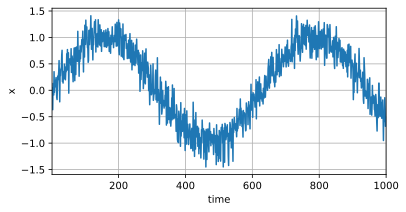

In [13]:
%matplotlib inline
import torch
from torch import nn
from d2l import torch as d2l
T = 1000  # 总共产生1000个点
time = torch.arange(1, T + 1, dtype=torch.float32)
x = torch.sin(0.01 * time) + torch.normal(0, 0.2, (T,))
d2l.plot(time, [x], 'time', 'x', xlim=[1, 1000], figsize=(6, 3))

In [14]:
tau = 4
features = torch.zeros((T - tau, tau)) # features(样本数量，窗口长度)
for i in range(tau):
    features[:, i] = x[i: T - tau + i]
labels = x[tau:].reshape((-1, 1))

In [15]:
batch_size, n_train = 16, 600
# 只有前n_train个样本用于训练
train_iter = d2l.load_array((features[:n_train], labels[:n_train]),
                            batch_size, is_train=True)

In [16]:
# 初始化网络权重的函数
def init_weights(m):
    if type(m) == nn.Linear:
        nn.init.xavier_uniform_(m.weight)

# 一个简单的多层感知机
def get_net():
    net = nn.Sequential(nn.Linear(4, 10),
                        nn.ReLU(),
                        nn.Linear(10, 1))
    net.apply(init_weights)
    return net

# 平方损失。注意：MSELoss计算平方误差时不带系数1/2
loss = nn.MSELoss(reduction='none')

In [17]:
def train(net, train_iter, loss, epochs, lr):
    trainer = torch.optim.Adam(net.parameters(), lr)
    for epoch in range(epochs):
        for X, y in train_iter:
            trainer.zero_grad()
            l = loss(net(X), y)
            l.sum().backward()
            trainer.step()
        print(f'epoch {epoch + 1}, '
              f'loss: {d2l.evaluate_loss(net, train_iter, loss):f}')

net = get_net()
train(net, train_iter, loss, 5, 0.01)

epoch 1, loss: 0.073671
epoch 2, loss: 0.061313
epoch 3, loss: 0.057239
epoch 4, loss: 0.056000
epoch 5, loss: 0.055306


由于训练损失很小，因此我们期望模型能有很好的工作效果。
让我们看看这在实践中意味着什么。
首先是检查[**模型预测下一个时间步**]的能力，
也就是*单步预测*（one-step-ahead prediction）。

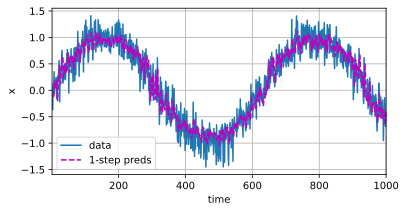

In [18]:
onestep_preds = net(features)
d2l.plot([time, time[tau:]],
         [x.detach().numpy(), onestep_preds.detach().numpy()], 'time',
         'x', legend=['data', '1-step preds'], xlim=[1, 1000],
         figsize=(6, 3))

正如我们所料，单步预测效果不错。
即使这些预测的时间步超过了$600+4$（`n_train + tau`），
其结果看起来仍然是可信的。
然而有一个小问题：如果数据观察序列的时间步只到$604$，
我们需要一步一步地向前迈进：
$$
\hat{x}_{605} = f(x_{601}, x_{602}, x_{603}, x_{604}), \\
\hat{x}_{606} = f(x_{602}, x_{603}, x_{604}, \hat{x}_{605}), \\
\hat{x}_{607} = f(x_{603}, x_{604}, \hat{x}_{605}, \hat{x}_{606}),\\
\hat{x}_{608} = f(x_{604}, \hat{x}_{605}, \hat{x}_{606}, \hat{x}_{607}),\\
\hat{x}_{609} = f(\hat{x}_{605}, \hat{x}_{606}, \hat{x}_{607}, \hat{x}_{608}),\\
\ldots
$$

通常，对于直到$x_t$的观测序列，其在时间步$t+k$处的预测输出$\hat{x}_{t+k}$
称为$k$*步预测*（$k$-step-ahead-prediction）。
由于我们的观察已经到了$x_{604}$，它的$k$步预测是$\hat{x}_{604+k}$。
换句话说，我们必须使用我们自己的预测（而不是原始数据）来[**进行多步预测**]。
让我们看看效果如何。

In [19]:
multistep_preds = torch.zeros(T)
multistep_preds[: n_train + tau] = x[: n_train + tau]
for i in range(n_train + tau, T):
    multistep_preds[i] = net(
        multistep_preds[i - tau:i].reshape((1, -1)))

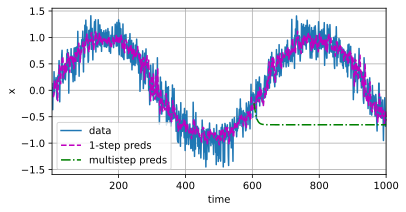

In [20]:
d2l.plot([time, time[tau:], time[n_train + tau:]],
         [x.detach().numpy(), onestep_preds.detach().numpy(),
          multistep_preds[n_train + tau:].detach().numpy()], 'time',
         'x', legend=['data', '1-step preds', 'multistep preds'],
         xlim=[1, 1000], figsize=(6, 3))

如上面的例子所示，绿线的预测显然并不理想。
经过几个预测步骤之后，预测的结果很快就会衰减到一个常数。
为什么这个算法效果这么差呢？事实是由于错误的累积：
假设在步骤$1$之后，我们积累了一些错误$\epsilon_1 = \bar\epsilon$。
于是，步骤$2$的输入被扰动了$\epsilon_1$，
结果积累的误差是依照次序的$\epsilon_2 = \bar\epsilon + c \epsilon_1$，
其中$c$为某个常数，后面的预测误差依此类推。
因此误差可能会相当快地偏离真实的观测结果。
例如，未来$24$小时的天气预报往往相当准确，
但超过这一点，精度就会迅速下降。
我们将在本章及后续章节中讨论如何改进这一点。

基于$k = 1, 4, 16, 64$，通过对整个序列预测的计算，
让我们[**更仔细地看一下$k$步预测**]的困难。

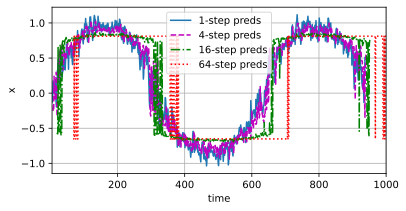

In [21]:
max_steps = 64
features = torch.zeros((T - tau - max_steps + 1, tau + max_steps))
# 列i（i<tau）是来自x的观测，其时间步从（i）到（i+T-tau-max_steps+1）
for i in range(tau):
    features[:, i] = x[i: i + T - tau - max_steps + 1]

# 列i（i>=tau）是来自（i-tau+1）步的预测，其时间步从（i）到（i+T-tau-max_steps+1）
for i in range(tau, tau + max_steps):
    features[:, i] = net(features[:, i - tau:i]).reshape(-1)
steps = (1, 4, 16, 64)
d2l.plot([time[tau + i - 1: T - max_steps + i] for i in steps],
         [features[:, (tau + i - 1)].detach().numpy() for i in steps], 'time', 'x',
         legend=[f'{i}-step preds' for i in steps], xlim=[5, 1000],
         figsize=(6, 3))

以上例子清楚地说明了当我们试图预测更远的未来时，预测的质量是如何变化的。
虽然“$4$步预测”看起来仍然不错，但超过这个跨度的任何预测几乎都是无用的。

## 文本预处理

我们将解析文本的常见预处理步骤。
这些步骤通常包括：

1. 将文本作为字符串加载到内存中。
1. 将字符串拆分为词元（如单词和字符）。
1. 建立一个词表，将拆分的词元映射到数字索引。
1. 将文本转换为数字索引序列，方便模型操作。

In [1]:
import collections
import re
from d2l import torch as d2l

collections和re是Python标准库，不需要额外安装

`import collections`：提供一些方便的数据容器。处理文本时，常用其中的 `Counter` 统计词频：

In [ ]:
tokens = ["hello", "world", "hello"]
counter = collections.Counter(tokens)

print(counter)
# Counter({'hello': 2, 'world': 1})

**`import re`：提供正则表达式功能，用于匹配、替换或拆分文本。**

例如，将连续的非英文字母替换为一个空格，再转成小写：

In [ ]:
text = "Hello, World! 123"
text = re.sub('[^A-Za-z]+', ' ', text).strip().lower()

print(text)
# hello world

其中：

- `[^A-Za-z]`：匹配一个非英文字母字符。
- `+`：匹配连续一个或多个。
- `re.sub(模式, 替换内容, 原文本)`：替换匹配到的内容。
- `.strip()`：去除首尾空白。
- `.lower()`：转为小写。

在文本预处理里，这两个库经常分别用于**统计词频**和**清洗文本**。

| 正则写法    | 含义                     | 匹配示例                    |
| ----------- | ------------------------ | --------------------------- |
| `abc`       | 匹配文字 `abc`           | `abc`                       |
| `[a-z]`     | 一个小写英文字母         | `a`、`k`                    |
| `[A-Za-z]`  | 一个英文字母             | `a`、`K`                    |
| `[^A-Za-z]` | 一个非英文字母字符       | `3`、`!`、空格              |
| `\d`        | 一个数字                 | `8`                         |
| `\s`        | 一个空白字符             | 空格、换行等                |
| `+`         | 前面的内容出现至少一次   | `\d+` 匹配 `123`            |
| `*`         | 前面的内容出现零次或多次 | `ab*` 匹配 `a`、`ab`、`abb` |

### 读取数据集

首先，我们从H.G.Well的[时光机器](https://www.gutenberg.org/ebooks/35)中加载文本。
这是一个相当小的语料库，只有30000多个单词，但足够我们小试牛刀，
而现实中的文档集合可能会包含数十亿个单词。
下面的函数(**将数据集读取到由多条文本行组成的列表中**)，其中每条文本行都是一个字符串。
为简单起见，我们在这里忽略了标点符号和字母大写。

In [2]:
#@save
d2l.DATA_HUB['time_machine'] = (d2l.DATA_URL + 'timemachine.txt',
                                '090b5e7e70c295757f55df93cb0a180b9691891a')

def read_time_machine():  #@save
    """将时间机器数据集加载到文本行的列表中"""
    with open(d2l.download('time_machine'), 'r') as f:
        lines = f.readlines()
    return [re.sub('[^A-Za-z]+', ' ', line).strip().lower() for line in lines]

lines = read_time_machine()
print(f'# 文本总行数: {len(lines)}')
print(lines[0])
print(lines[10])

# 文本总行数: 3221
the time machine by h g wells
twinkled and his usually pale face was flushed and animated the


## 词元化

下面的`tokenize`函数将文本行列表（`lines`）作为输入，
列表中的每个元素是一个文本序列（如一条文本行）。
[**每个文本序列又被拆分成一个词元列表**]，*词元*（token）是文本的基本单位。
最后，返回一个由词元列表组成的列表，其中的每个词元都是一个字符串（string）。

In [ ]:
def tokenize(lines, token='word'):  #@save
    """将文本行拆分为单词或字符词元"""
    if token == 'word':
        return [line.split() for line in lines]
    elif token == 'char':
        return [list(line) for line in lines]
    else:
        print('错误：未知词元类型：' + token)

tokens = tokenize(lines)
for i in range(11):
    print(tokens[i])